# 03 – Data preparation

CRISP-DM phase 3. Input: the SQLite database (`data/hockey.db`). Output: `data/processed/features.csv`, one row per (franchise, season) with **leak-free** features, and `data/processed/feature_lists.json`.

| Section | Rubric criterion |
|---|---|
| 1. Integration | Data integration (format conversion + entity matching) |
| 2. Data quality | Data quality dimensions (all 6) |
| 3. Era choice | Sampling for domain |
| 4. Feature engineering | Feature engineering (aggregation + business concepts) |
| 5. Missing values | Missing data |
| 6. Outliers | Outliers |
| 7. Redundancy | Redundancy |
| 8. Transformations | Transformation for algorithms (rescaling, discretisation) |

**The golden rule:** a feature of season *t* only uses information available the day before season *t* starts. Season-*t* statistics are only used as **targets**.

In [1]:
import sys, json, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50, "display.width", 200, "display.precision", 3)
from features import (connect, run_sql, read_checks, build_dataset, ALL_FEATURES, TEAM_FEATURES,
                      ROSTER_FEATURES, COACH_FEATURES, ROSTER_KNOWN_COLS)
from validation import MIN_YEAR, TEST_YEARS
con = connect()
q = lambda sql: pd.read_sql(sql, con)

## 1. Data integration

### 1.1 Matching entities between sources

| Entity | Problem | Solution |
|---|---|---|
| Team over time | `tmID` changes when a team relocates (e.g. Quebec → Colorado) | Follow the team with `franchID`, which never changes |
| Coach ↔ person | `Coaches` has only `coachID` | Join `Master` on `coachID` → birth year, `playerID` (was he a player?), `hofID` |
| Player ↔ person | `Scoring`/`Goalies` have only `playerID` | Join `Master` on `playerID` → birth year, weight |
| Player ↔ awards | — | Join `AwardsPlayers` on (`playerID`, `year`) |
| Coach ↔ awards / HOF | — | Join `AwardsCoaches` on `coachID`; `HOF` on `hofID` (only inductions **before** season *t*) |
| Team ↔ splits | home/road, month by month | Join `TeamSplits` on (`year`, `tmID`, `lgID`) |
| Player/coach ↔ franchise | `Scoring`, `Goalies`, `Coaches` have `tmID` only | Join `Teams` on (`year`, `tmID`, `lgID`) to get `franchID` |

In [2]:
# Franchises that played under more than one tmID (relocations / renames)
q("""SELECT franchID, GROUP_CONCAT(DISTINCT tmID) AS tmIDs, MIN(year) AS first, MAX(year) AS last
     FROM Teams WHERE lgID='NHL' AND year >= 1970 GROUP BY franchID HAVING COUNT(DISTINCT tmID) > 1""")

,franchID,tmIDs,first,last
0,ANA,"ANA,AND",1993,2009
1,CAL,"ATF,CAL",1972,2009
2,CAR,"HAR,CAR",1979,2009
3,CLE,"CLF,CLE",1970,1977
4,COL,"QUE,COL",1979,2009
5,DAL,"MNS,DAL",1970,2009
6,NJD,"KCS,COR,NJD",1974,2009
7,PHO,"WIN,PHO",1979,2009


In [3]:
# How well do the joins match? (share of rows that find their partner)
match = q("""
SELECT 'Coaches -> Master'  AS join_, AVG(m.coachID IS NOT NULL) AS match_rate
  FROM Coaches c LEFT JOIN (SELECT DISTINCT coachID FROM Master) m ON m.coachID = c.coachID WHERE c.year >= 1979
UNION ALL
SELECT 'Scoring -> Master (birth year)', AVG(m.birthYear IS NOT NULL)
  FROM Scoring s LEFT JOIN Master m ON m.playerID = s.playerID WHERE s.year >= 1979 AND s.lgID='NHL'
UNION ALL
SELECT 'Scoring -> Teams (franchID)', AVG(t.franchID IS NOT NULL)
  FROM Scoring s LEFT JOIN Teams t ON t.year=s.year AND t.tmID=s.tmID AND t.lgID=s.lgID WHERE s.year >= 1979 AND s.lgID='NHL'
UNION ALL
SELECT 'Teams -> TeamSplits', AVG(s.tmID IS NOT NULL)
  FROM Teams t LEFT JOIN TeamSplits s ON s.year=t.year AND s.tmID=t.tmID AND s.lgID=t.lgID WHERE t.year >= 1979 AND t.lgID='NHL'
UNION ALL
SELECT 'Coach is a former player (Master.playerID)', AVG(m.playerID IS NOT NULL)
  FROM (SELECT DISTINCT coachID FROM Coaches WHERE year >= 1979 AND lgID='NHL') c JOIN Master m ON m.coachID = c.coachID
""")
match

,join_,match_rate
0,Coaches -> Master,1.000
1,Scoring -> Master (birth year),1.000
2,Scoring -> Teams (franchID),1.000
3,Teams -> TeamSplits,1.000
4,Coach is a former player (Master.playerID),0.704


### 1.2 Converting formats

- **Birth date → age at the start of season *t*:** `year − birthYear` (weighted by games played for a roster).
- **Ties and overtime losses:** `T` (until 2003) and `OTL` (from 1999) are both "a non-win worth one point" → merged into `ties_otl`.
- **Per-game rates:** every count is divided by `G`, because seasons have different lengths (1994: 48 games; 2005+: 82 games).
- **Playoff code → ordinal depth:** the round codes changed with the format (`PRE/QF/SF` until 1980, `DSF/DF/CF` until 1992, `CQF/CSF/CF` after) → one ordinal scale `playoff_depth` 0 (missed) … 5 (won the Stanley Cup).

All this is done **in SQL** (see `sql/team_season.sql`, `roster_season.sql`, `goalie_season.sql`, `coach_season.sql`). Example:

In [4]:
print(open("../sql/coach_season.sql").read())

-- One row per NHL franchise-season: who started the season, who finished it,
-- and whether the coach changed during the season.
-- Coaches.stint is the order of the coaches of a team within a season (1 = opening coach).
-- Co-coaches share the same stint (Detroit 1998), so a mid-season change is
-- MAX(stint) > 1, not COUNT(*) > 1.
-- Teams are followed by franchID because tmID changes when a team relocates.
WITH c AS (
    SELECT t.franchID, c.year, c.coachID, c.stint, c.g,
           ROW_NUMBER() OVER (PARTITION BY t.franchID, c.year ORDER BY c.stint ASC,  c.g DESC) AS rn_first,
           ROW_NUMBER() OVER (PARTITION BY t.franchID, c.year ORDER BY c.stint DESC, c.g DESC) AS rn_last
    FROM Coaches c
    JOIN Teams t ON t.year = c.year AND t.tmID = c.tmID AND t.lgID = c.lgID
    WHERE c.lgID = 'NHL'
)
SELECT franchID, year,
       MAX(stint)                                   AS n_stints,
       COUNT(DISTINCT coachID)                      AS n_coaches,
       MAX(CASE WHEN rn_firs

## 2. Data quality: the 6 dimensions

All checks are SQL queries in `sql/data_quality.sql`.

In [5]:
checks = read_checks(con)
summary = pd.DataFrame({"rows_flagged": {k: len(v) for k, v in checks.items()}})
summary

,rows_flagged
uniqueness_teams,0
uniqueness_master,0
consistency_games,0
consistency_points,0
consistency_coach_games,1
accuracy_goals,133
validity_values,0
validity_save_pct,0
timeliness_coverage,10


In [6]:
for k in ["consistency_games", "consistency_points", "consistency_coach_games", "accuracy_goals", "validity_values"]:
    print(f"--- {k}: {len(checks[k])} rows"); display(checks[k].head(5))

--- consistency_games: 0 rows


,year,tmID,G,W,L,T,OTL,sum_results


--- consistency_points: 0 rows


,year,tmID,Pts,expected


--- consistency_coach_games: 1 rows


,year,tmID,G,coach_g
0,1998,DET,82,87.0


--- accuracy_goals: 133 rows


,year,tmID,GF,player_goals,diff
0,2005,ANA,254,251.0,3.0
1,2005,ATL,281,276.0,5.0
2,2005,BUF,281,276.0,5.0
3,2005,CAR,294,286.0,8.0
4,2005,CBS,223,215.0,8.0


--- validity_values: 0 rows


,year,tmID,G,W,L,GF,GA,rank


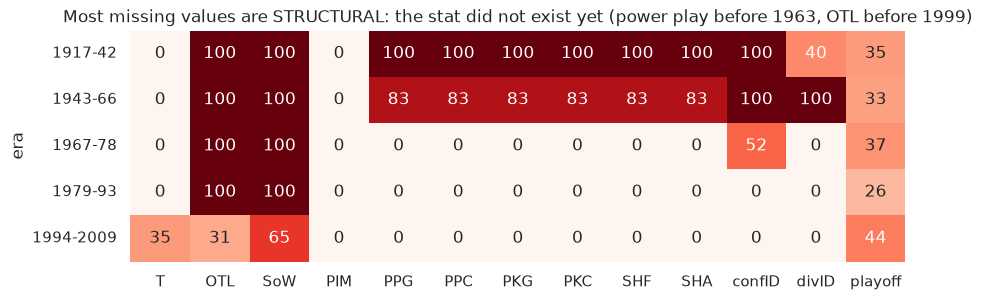

Shots against (needed for save%) missing in most rows until: 1981


In [7]:
# Completeness: % missing per column of Teams, by era
teams = q("SELECT * FROM Teams WHERE lgID='NHL'")
teams["era"] = pd.cut(teams.year, [1916, 1942, 1966, 1978, 1993, 2009],
                      labels=["1917-42", "1943-66", "1967-78", "1979-93", "1994-2009"])
cols = ["T", "OTL", "SoW", "PIM", "PPG", "PPC", "PKG", "PKC", "SHF", "SHA", "confID", "divID", "playoff"]
miss = teams.groupby("era")[cols].apply(lambda d: d.isna().mean() * 100)
fig, ax = plt.subplots(figsize=(10, 3))
sns.heatmap(miss, annot=True, fmt=".0f", cmap="Reds", cbar=False, ax=ax)
ax.set_title("Most missing values are STRUCTURAL: the stat did not exist yet (power play before 1963, OTL before 1999)")
plt.show()
gl = q("SELECT year, AVG(SA IS NULL)*100 AS pct_missing_SA FROM Goalies WHERE lgID='NHL' AND year >= 1975 GROUP BY year")
print("Shots against (needed for save%) missing in most rows until:", gl[gl.pct_missing_SA > 50].year.max())

In [8]:
checks["timeliness_coverage"]

,tbl,first,last,n_years
0,Teams,1909,2009,100
1,Scoring,1909,2009,100
2,Goalies,1909,2009,100
3,Coaches,1909,2009,100
4,TeamSplits,1909,2009,100
5,TeamsHalf,1916,1920,5
6,ScoringSup,1987,1990,4
7,GoaliesShootout,2005,2009,5
8,AwardsPlayers,1917,2009,92
9,AwardsCoaches,1930,2009,53


**Data quality table** (the annex slide):

| Dimension | Check | Result | Action |
|---|---|---|---|
| Completeness | % missing per column and era | Power-play/penalty stats missing before 1963; `OTL` only from 1999; shots against (save%) missing before 1982; coach birth year sometimes missing | Restrict to 1979+; save% left missing → imputed inside the pipeline; structural vs. real missing values separated (§5) |
| Accuracy | Team `GF` vs. sum of player goals | 133 team-seasons differ by more than 2 goals, **all from 2005 on**: the shootout-winning goal counts in the team's GF but not for any player | Use team-level `GF` from `Teams` |
| Consistency | `W+L+T+OTL = G`; `Pts = 2W+T+OTL`; coach games add up to team games | See the checks above | Points% computed from `Pts` and `G`; coach changes from `stint` (not from game counts) |
| Uniqueness | Duplicate (year, tmID); duplicate people in Master | No duplicate team-seasons; homonyms in Master are different people (different IDs) | Keys are (`franchID`, `year`) and `playerID`/`coachID` |
| Validity | Negative values, ranks out of range, GA > SA | See `validity_*` | None needed in the modern era |
| Timeliness | Years covered by each table | Data ends in 2009; `TeamsHalf`, `*SC`, `ScoringSup`, shootout tables cover only a few seasons | Drop those tables; predict 2010; train on 1979+ (§3) |

Extra note found in data understanding: Detroit 1998 has two co-coaches with `stint = 1` (Lewis and Smith replaced Bowman for 5 games). So a mid-season change is defined as `MAX(stint) > 1`, not "more than one row".

## 3. Sampling for the domain: which seasons to use?

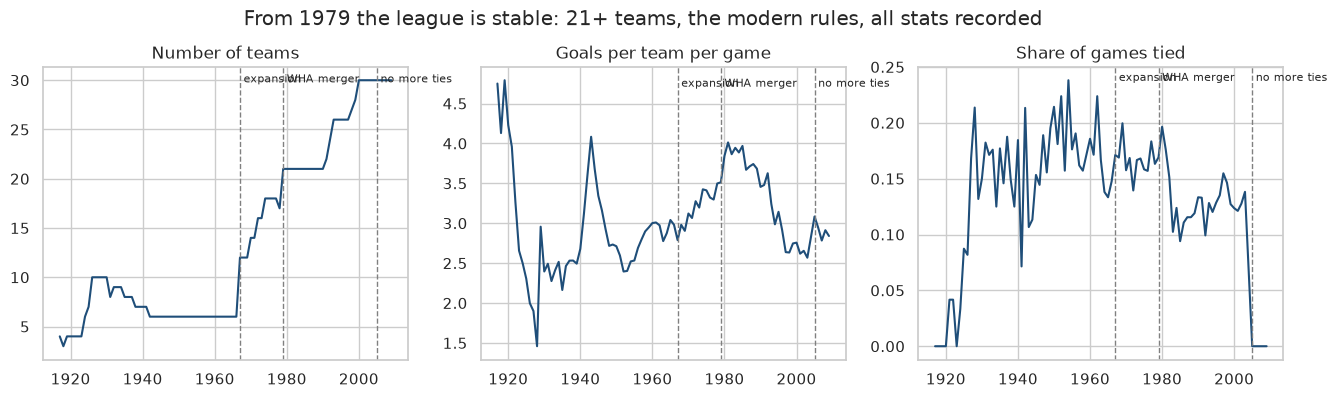

In [9]:
t = q("""SELECT year, COUNT(*) AS n_teams, AVG(G) AS games, SUM(GF)*1.0/SUM(G) AS goals_pg,
               SUM(COALESCE(T,0))*1.0/SUM(G) AS tie_rate FROM Teams WHERE lgID='NHL' GROUP BY year""")
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col, title in zip(axes, ["n_teams", "goals_pg", "tie_rate"],
                          ["Number of teams", "Goals per team per game", "Share of games tied"]):
    ax.plot(t.year, t[col], color="#1f4e79")
    for y, lab in [(1967, "expansion"), (1979, "WHA merger"), (2005, "no more ties")]:
        ax.axvline(y, ls="--", color="grey", lw=1); ax.text(y + 1, ax.get_ylim()[1] * .95, lab, fontsize=8)
    ax.set_title(title)
fig.suptitle("From 1979 the league is stable: 21+ teams, the modern rules, all stats recorded", y=1.03)
plt.show()

**Decision: NHL only, seasons 1979–2009 (training starts in 1979, test seasons 2000–2009).**

- Other leagues (NHA, PCHA, WCHL, WHA) are not the competition we predict.
- 1979 is the WHA merger: from there the NHL has 21–30 teams, the same scoring stats and the playoff structure close to the current one.
- Before 1967 there were only 6 teams, so "ranking" and "coach change" mean something very different.
- Earlier seasons are still used **only to compute lag features** (e.g. the 1978 season gives the lags of 1979).

The test seasons (2000–2009, without 2004) all have 30 teams with 8 playoff places per conference.

## 4. Build the dataset (feature engineering)

`src/features.py` joins all SQL outputs and computes the features with a **one-season lag** per `franchID`.

In [10]:
df = build_dataset(roster_known=True)
model = df[(df.year >= MIN_YEAR)]
print(df.shape, "| modelling rows (1979-2009):", (model.is_future == 0).sum(), "| future rows (2010):", model.is_future.sum())
model[["year", "franchID", "name", "pts_pct", "pts_pct_lag1", "luck_lag1", "coach", "coach_tenure", "coach_change_any"]].tail(5)

(1295, 121) | modelling rows (1979-2009): 753 | future rows (2010): 30


,year,franchID,name,pts_pct,pts_pct_lag1,luck_lag1,coach,coach_tenure,coach_change_any
1290,2010,TBL,Tampa Bay Lightning,NaN,0.488,0.077,tocchri01c,2,NaN
1291,2010,TOR,Toronto Maple Leafs,NaN,0.451,0.060,wilsoro02c,2,NaN
1292,2010,VAN,Vancouver Canucks,NaN,0.628,0.028,vigneal01c,4,NaN
1293,2010,WAS,Washington Capitals,NaN,0.738,0.087,boudrbr01c,3,NaN
1294,2010,WPG,Atlanta Thrashers,NaN,0.506,0.051,anderjo01c,2,NaN


### Feature dictionary

| Group | Feature | How it is built | Hockey meaning |
|---|---|---|---|
| Team (simple) | `pts_pct_lag1`, `pts_pct_lag2` | Points / (2·games) at t-1, t-2 | How good the team was |
| Team (aggregation) | `pts_pct_ma3`, `gd_pg_ma3` | Mean of t-1…t-3 | Stable level, less noise than one season |
| Team | `pts_trend` | pts% t-1 − pts% t-2 | Improving or declining team |
| Business concept | `pyth_pct_lag1` | GF²/(GF²+GA²) at t-1 | Points the team "deserved" from its goals |
| Business concept | `luck_lag1` | pts% − Pythagorean at t-1 | Luck: tends to revert to zero the next season |
| Business concept | `pp_pct_lag1`, `pk_pct_lag1` | PPG/PPC, 1 − PKG/PKC | Special teams quality |
| Business concept | `late_form_lag1` | win% Jan–Apr − season win% (TeamSplits) | Did the team finish strongly? |
| Team | `home_win_pct_lag1`, `road_win_pct_lag1` | TeamSplits | Home advantage |
| Team | `made_playoffs_lag1`, `playoff_depth_lag1`, `playoff_streak_miss` | Teams.playoff | Success / frustration of the fans |
| Roster (aggregation) | `roster_pts_pg_lag1`, `top_scorer_pts_lag1`, `n_20goal_lag1`, `n_60pts_lag1` | Scoring, summed per franchise | Offensive talent |
| Roster (integration) | `avg_age_lag1`, `avg_weight_lag1` | Scoring ⨝ Master, weighted by games | Old / young, physical team |
| Roster (integration) | `n_award_winners_lag1` | Scoring ⨝ AwardsPlayers | Star players |
| Goalie (integration) | `team_sv_pct_lag1`, `main_goalie_sv_pct_lag1`, `main_goalie_share_lag1` | Goalies, goalie with most minutes | Goaltending is the most important position |
| Coach (known pre-season) | `new_coach` | Coach opening t ≠ coach ending t-1 | A new coach was hired in the summer |
| Coach (aggregation) | `coach_tenure` | Consecutive seasons with this franchise | Grace period vs. "worn-out" coach |
| Coach (aggregation) | `coach_career_g`, `coach_career_win_pct`, `coach_n_teams`, `coach_times_replaced` | All Coaches rows before t | Experience and track record |
| Coach (integration) | `coach_awards`, `coach_former_player`, `coach_hof_player`, `coach_age` | AwardsCoaches, Master, HOF | Reputation |
| Franchise | `franchise_coaches_5y` | Distinct coaches in t-5…t-1 | Impatient owners |
| Interaction | `tenure_x_badness` | tenure × (0.5 − pts% t-1) | Long-tenured coach of a bad team (found in notebook 02) |
| Flag | `is_new_team`, `coach_rookie` | No history | Missing-value flags |
| Optional (roster known) | `rk_prev_pts`, `rk_n20goal`, `rk_share_rookies`, `rk_share_returning` | Players of season t, their t-1 stats | Only if the professor confirms the roster is known |

**Why HOF is not used for players:** a player enters the Hall of Fame *after* his career, so "number of future Hall-of-Famers on the roster" would be information from the future (leakage). For coaches we only count inductions that happened before season *t*.

## 5. Missing values

In [11]:
hist = model[model.is_future == 0]
mv = (hist[ALL_FEATURES].isna().mean() * 100).sort_values(ascending=False)
mv = mv[mv > 0].to_frame("% missing")
def kind(c):
    miss = hist[c].isna()
    if "sv_pct" in c:
        return "structural: shots against not recorded before 1982"
    if c == "coach_career_win_pct":
        return "structural: rookie coach has no career"
    if hist.loc[miss, "is_new_team"].mean() > .5 or hist.loc[miss, "seasons_in_league"].max() <= 1:
        return "structural: new team has no previous season"
    return "real (e.g. missing birth year)"
mv["type"] = [kind(c) for c in mv.index]
mv

,% missing,type
coach_career_win_pct,12.483,structural: rookie coach has no career
main_goalie_sv_pct_lag1,12.351,structural: shots against not recorded before ...
team_sv_pct_lag1,12.351,structural: shots against not recorded before ...
pts_trend,3.453,structural: new team has no previous season
pp_pct_lag1,1.726,structural: new team has no previous season
pk_pct_lag1,1.726,structural: new team has no previous season
ga_pg_lag1,1.726,structural: new team has no previous season
gd_pg_lag1,1.726,structural: new team has no previous season
gd_pg_ma3,1.726,structural: new team has no previous season
pyth_pct_lag1,1.726,structural: new team has no previous season


Strategy (all fitted on the training seasons only, inside the pipeline of each model):

1. **Expansion teams** (no previous season): `pts_pct_lag1/lag2/ma3` are filled with a **domain prior**, the mean first-season points% of the expansion teams that played **before** season *t* (≈ 0.38: new teams are weak). The flag `is_new_team` lets the model learn the rest.
2. **Rookie coaches:** `coach_career_win_pct` is undefined → flag `coach_rookie`, the value is imputed.
3. **Everything else:** `KNNImputer(k=10)` inside the `Pipeline`, so neighbours are searched among training rows only.

Below: is a model-based imputer worth it? (Ridge, all features, walk-forward.)

In [12]:
from sklearn.linear_model import Ridge
from imblearn.pipeline import Pipeline
from models import _prep
from experiment import run_regression
res = []
for imp in ["median", "knn", "iterative"]:
    s, _, _ = run_regression(hist, ALL_FEATURES, {imp: (Pipeline(_prep(imputer=imp) + [("m", Ridge(alpha=10))]), {})})
    res.append(s[["model", "spearman", "pts_mae"]])
pd.concat(res).groupby("model").mean().sort_values("spearman", ascending=False)

,spearman,pts_mae
model,,
iterative,0.521,0.060
median,0.514,0.061
knn,0.511,0.060


The three imputers give almost the same result, because only ~2–12% of the values are missing and most of them are structural. We keep `KNNImputer` (model-based, uses similar teams) as the default.

## 6. Outliers

**Identify** (IQR rule per feature, Isolation Forest for multivariate outliers), **discuss** in hockey terms, **address**.

In [13]:
num = hist[ALL_FEATURES].select_dtypes("number")
Q1, Q3 = num.quantile(.25), num.quantile(.75)
iqr_out = ((num < Q1 - 1.5 * (Q3 - Q1)) | (num > Q3 + 1.5 * (Q3 - Q1))).sum().sort_values(ascending=False)
iqr_out[iqr_out > 0].head(10).to_frame("n outliers (IQR rule)")

,n outliers (IQR rule)
coach_awards,187
changed_during_lag1,148
playoff_streak_miss,101
tenure_x_badness,96
coach_rookie,94
n_award_winners_lag1,74
coach_n_teams,63
coach_tenure,45
coach_hof_player,34
coach_career_g,30


In [14]:
from sklearn.ensemble import IsolationForest
season_cols = ["pts_pct", "gf_pg", "ga_pg", "pim_pg", "pp_pct", "pk_pct", "G"]
s = hist.dropna(subset=season_cols)
iso = IsolationForest(contamination=0.02, random_state=0).fit(s[season_cols])
s = s.assign(anomaly=-iso.score_samples(s[season_cols]))
s.nlargest(12, "anomaly")[["year", "name", "G", "pts_pct", "gf_pg", "ga_pg", "pim_pg", "anomaly"]]

,year,name,G,pts_pct,gf_pg,ga_pg,pim_pg,anomaly
844,1994,Detroit Red Wings,48.0,0.729,3.750,2.438,19.417,0.664
804,1992,San Jose Sharks,84.0,0.143,2.595,4.929,25.405,0.648
836,1994,Mighty Ducks of Anaheim,48.0,0.385,2.604,3.417,15.229,0.627
852,1994,Ottawa Senators,48.0,0.240,2.438,3.625,15.604,0.626
645,1985,Detroit Red Wings,80.0,0.250,3.325,5.188,29.913,0.623
826,1993,Ottawa Senators,84.0,0.220,2.393,4.726,20.357,0.617
800,1992,Ottawa Senators,84.0,0.143,2.405,4.702,20.429,0.616
842,1994,Quebec Nordiques,48.0,0.677,3.854,2.792,16.042,0.609
841,1994,Chicago Blackhawks,48.0,0.552,3.250,2.396,23.396,0.604
646,1985,Edmonton Oilers,80.0,0.744,5.325,3.875,24.100,0.600


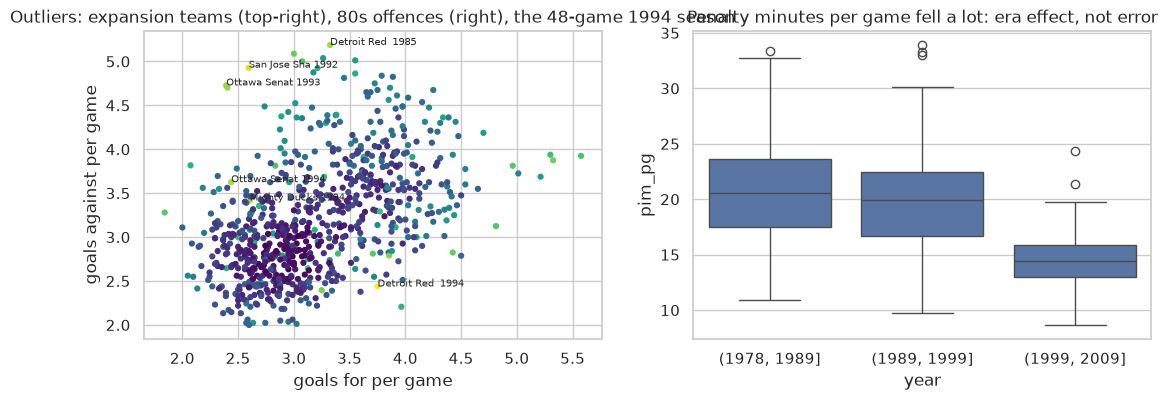

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(s.gf_pg, s.ga_pg, c=s.anomaly, cmap="viridis", s=12)
for _, r in s.nlargest(6, "anomaly").iterrows():
    axes[0].annotate(f"{r['name'][:12]} {r.year}", (r.gf_pg, r.ga_pg), fontsize=7)
axes[0].set(xlabel="goals for per game", ylabel="goals against per game",
            title="Outliers: expansion teams (top-right), 80s offences (right), the 48-game 1994 season")
sns.boxplot(data=hist, x=pd.cut(hist.year, [1978, 1989, 1999, 2009]), y="pim_pg", ax=axes[1])
axes[1].set_title("Penalty minutes per game fell a lot: era effect, not error")
plt.show()

**Discussion.**
- The most anomalous seasons are **real**, not errors, so they are **not deleted**:
  - the **1994 lockout season** (48 games instead of 84): the counts are low only because of the season length → fixed by working **per game**;
  - **expansion teams in their first seasons** (San Jose 1992 and Ottawa 1992, 0.14 points%): handled with the `is_new_team` flag and the expansion prior;
  - the **1980s** extremes: Edmonton 1985 (5.3 goals per game), Detroit 1985 (5.2 goals against), Calgary 1988 (30 penalty minutes per game).
- Penalty minutes changed by era: the model sees the year implicitly through the training window.

**Addressing them** (domain-dependent): (1) per-game normalisation; (2) a `Winsorizer` inside the pipeline that clips each feature to the 1%–99% quantiles **of the training seasons** (so a single extreme team does not dominate a linear model or kNN distance); (3) trees are naturally robust to outliers.

## 7. Redundancy: systematic removal

Rule: compute |Spearman ρ| between every pair of features **on the training era only (1979–1999)**. Repeatedly take the most correlated pair; if |ρ| > 0.9, drop the member that is **less correlated with the targets** (mean |ρ| with points% and with coach change, again on 1979–1999 only). Also drop constant columns. Using only the training era keeps the test seasons untouched.

In [16]:
cand = ALL_FEATURES + ROSTER_KNOWN_COLS
train_era = hist[hist.year < 2000][cand]
const = [c for c in cand if train_era[c].nunique() <= 1]
corr = train_era.drop(columns=const).corr(method="spearman").abs()
te = hist[hist.year < 2000]
relevance = pd.Series({c: np.nanmean([abs(te[c].corr(te.pts_pct, method="spearman")),
                                      abs(te[c].corr(te.coach_change_any, method="spearman"))]) for c in corr.columns})
THR = 0.9
dropped, keep = [], [c for c in cand if c not in const]
while True:
    sub = corr.loc[keep, keep].where(~np.eye(len(keep), dtype=bool))
    if sub.max().max() <= THR:
        break
    a, b = sub.stack().idxmax()
    victim = a if relevance[a] < relevance[b] else b
    dropped.append((victim, a if victim == b else b, round(sub.loc[a, b], 3)))
    keep.remove(victim)
print("constant:", const)
pd.DataFrame(dropped, columns=["dropped", "kept (its twin)", "|rho|"])

constant: []


,dropped,kept (its twin),|rho|
0,gd_pg_lag1,pyth_pct_lag1,0.996
1,gf_pg_lag1,roster_pts_pg_lag1,0.994
2,coach_career_g,coach_n_seasons,0.987
3,playoff_streak_miss,made_playoffs_lag1,0.982
4,pts_pct_ma3,gd_pg_ma3,0.981
5,win_pct_lag1,pts_pct_lag1,0.976
6,pyth_pct_lag1,pts_pct_lag1,0.962
7,main_goalie_sv_pct_lag1,team_sv_pct_lag1,0.938


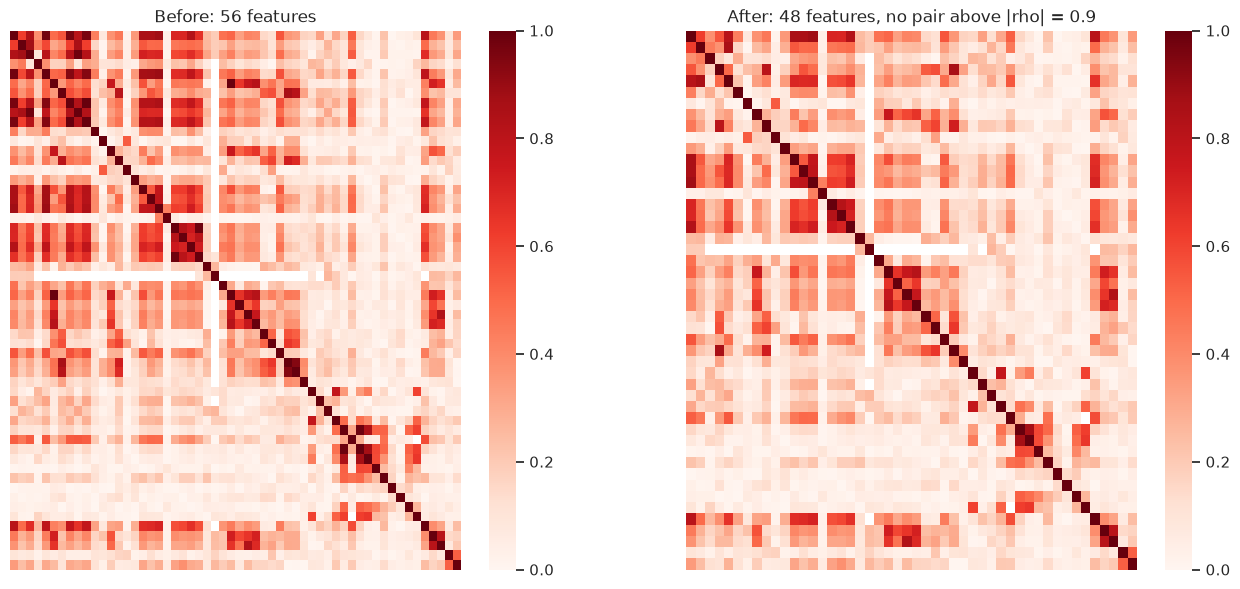

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
before = [c for c in cand if c not in const]
sns.heatmap(corr.loc[before, before], cmap="Reds", vmin=0, vmax=1, ax=axes[0], xticklabels=False, yticklabels=False)
axes[0].set_title(f"Before: {len(before)} features")
sns.heatmap(corr.loc[keep, keep], cmap="Reds", vmin=0, vmax=1, ax=axes[1], xticklabels=False, yticklabels=False)
axes[1].set_title(f"After: {len(keep)} features, no pair above |rho| = {THR}")
plt.show()

## 8. Transformations for the algorithms

| Transformation | Applied to | Why |
|---|---|---|
| `StandardScaler` (rescaling) | Ridge/Lasso, logistic regression, kNN, SVM, MLP | They use distances, dot products or gradients, so a feature measured in big units (games coached ≈ 1000) would dominate one in [0, 1] (points%) |
| No scaling | Decision tree, Random Forest, Gradient Boosting | A split `x < c` gives the same partition after any monotonic transformation |
| `KBinsDiscretizer(quantile, 4 bins)` | Naive Bayes (`CategoricalNB`) | NB with categorical features does not assume normal distributions (our features are skewed) |
| Domain discretisation | Coach tenure → new / established / veteran | Easier to read in white-box rules (see below) |

All of them live inside the `Pipeline` (`src/models.py`), so they are fitted on the training seasons only.

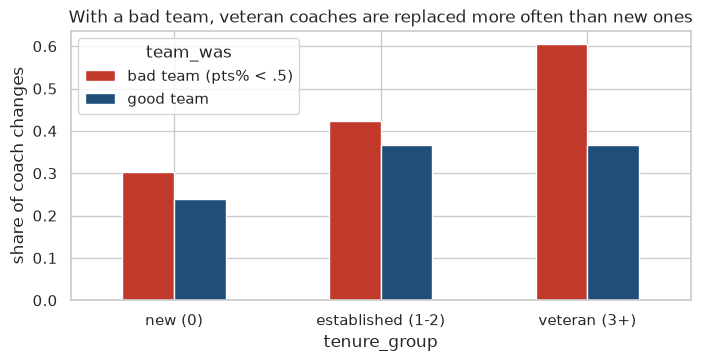

team_was,bad team (pts% < .5),good team
tenure_group,,
new (0),0.304,0.239
established (1-2),0.423,0.366
veteran (3+),0.606,0.367


In [18]:
tmp = hist.dropna(subset=["coach_change_any"]).copy()
tmp["tenure_group"] = pd.cut(tmp.coach_tenure, [-1, 0, 2, 100], labels=["new (0)", "established (1-2)", "veteran (3+)"])
tmp["team_was"] = np.where(tmp.pts_pct_lag1 < 0.5, "bad team (pts% < .5)", "good team")
tab = tmp.pivot_table(index="tenure_group", columns="team_was", values="coach_change_any", aggfunc="mean")
ax = tab.plot.bar(figsize=(8, 3.5), rot=0, color=["#c0392b", "#1f4e79"])
ax.set(ylabel="share of coach changes", title="With a bad team, veteran coaches are replaced more often than new ones")
plt.show(); tab

## 9. Save the dataset

In [19]:
import os
os.makedirs("../data/processed", exist_ok=True)
id_cols = ["year", "franchID", "tmID", "name", "confID", "divID", "is_future", "coach"]
targets = ["pts_pct", "made_playoffs", "league_rank", "conf_rank", "div_rank",
           "coach_change_during", "coach_change_end", "coach_change_any"]
out = model[id_cols + targets + cand]
out.to_csv("../data/processed/features.csv", index=False)
feats = [c for c in keep if c not in ROSTER_KNOWN_COLS]
json.dump({"features": feats, "roster_known": [c for c in keep if c in ROSTER_KNOWN_COLS],
           "dropped_redundant": [d[0] for d in dropped], "dropped_constant": const,
           "threshold": THR}, open("../data/processed/feature_lists.json", "w"), indent=1)
print(out.shape, "->", len(feats), "features (+", len([c for c in keep if c in ROSTER_KNOWN_COLS]), "optional roster-known)")

(783, 72) -> 44 features (+ 4 optional roster-known)


## Reflection on this phase

- **What went well:** most of the integration and aggregation is done in SQL and can be reproduced with one function call (`build_dataset()`). Every feature has a hockey meaning and uses only the past.
- **Decisions to confirm with the professor:** (1) the definition of "coach change" (three versions are built: `coach_change_during`, `coach_change_end`, `coach_change_any`); (2) whether the roster of the new season is known (the `rk_*` features).
- **Limitations:** trades during the season are not visible; save% does not exist before 1982; the 2010 coach is assumed to be the one who ended 2009.